## Data Preparation

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error

from statsmodels.tsa.seasonal import seasonal_decompose

In [2]:
data = pd.read_csv('data/taxi.csv', parse_dates=[0], index_col=0)
data.sort_index(inplace=True)
data.head()

,num_orders
datetime,
2018-03-01 00:00:00,9
2018-03-01 00:10:00,14
2018-03-01 00:20:00,28
2018-03-01 00:30:00,20
2018-03-01 00:40:00,32


In [3]:
data.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 26496 entries, 2018-03-01 00:00:00 to 2018-08-31 23:50:00
Data columns (total 1 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   num_orders  26496 non-null  int64
dtypes: int64(1)
memory usage: 414.0 KB


- The dataset contains only timestamps and the number of orders. There are no missing values.

In [4]:
data_1h = data.resample('1h').sum()

In [5]:
data_1h.head()

,num_orders
datetime,
2018-03-01 00:00:00,124
2018-03-01 01:00:00,85
2018-03-01 02:00:00,71
2018-03-01 03:00:00,66
2018-03-01 04:00:00,43


In [6]:
data_1h.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 4416 entries, 2018-03-01 00:00:00 to 2018-08-31 23:00:00
Freq: h
Data columns (total 1 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   num_orders  4416 non-null   int64
dtypes: int64(1)
memory usage: 69.0 KB


- Orders are aggregated into hourly totals to match the prediction target.

## Exploratory Analysis

In [7]:
data_1h.describe()

,num_orders
count,4416.000000
mean,84.422781
std,45.023853
min,0.000000
25%,54.000000
50%,78.000000
75%,107.000000
max,462.000000


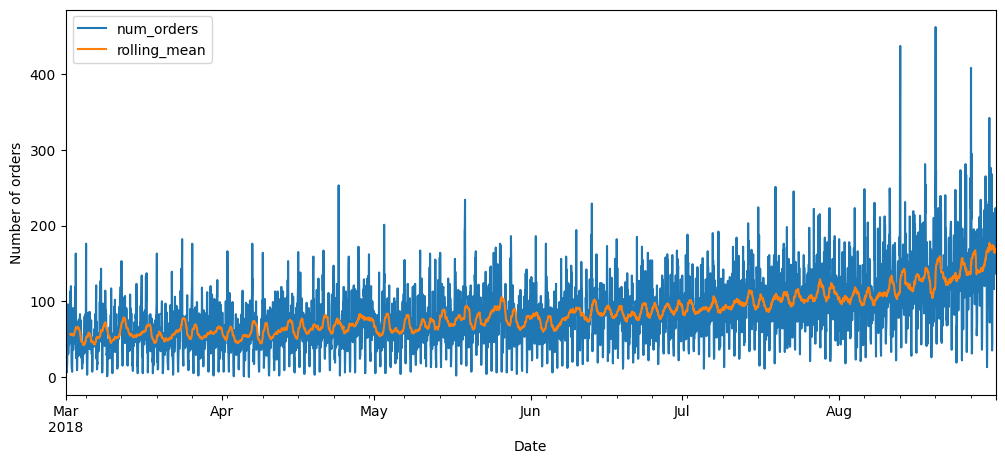

In [8]:
data_1h['rolling_mean'] = data_1h['num_orders'].rolling(24).mean()

data_1h[['num_orders', 'rolling_mean']].plot(figsize=(12, 5))
plt.xlabel('Date')
plt.ylabel('Number of orders')
plt.show()

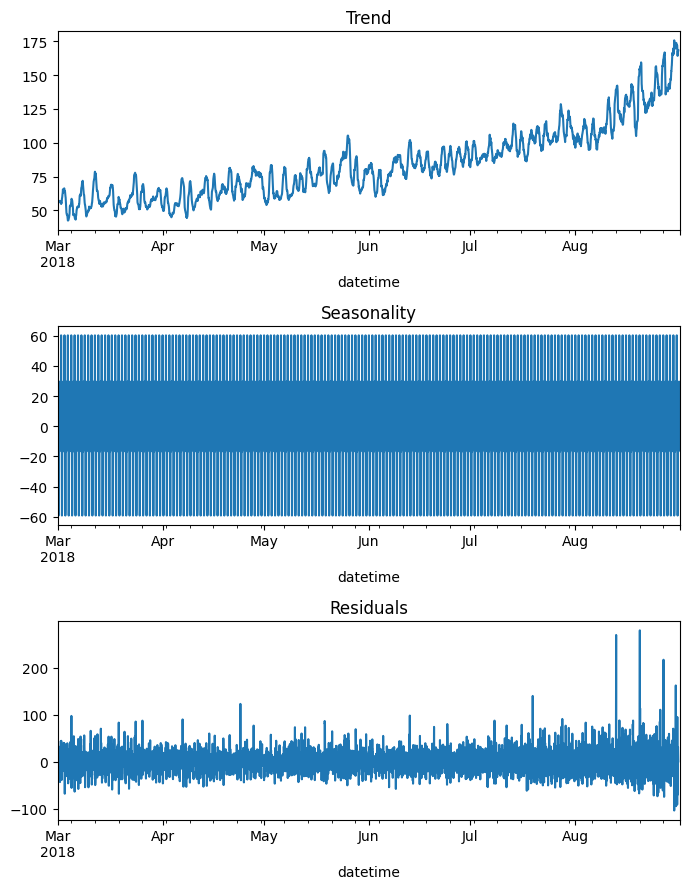

In [9]:
decomposed = seasonal_decompose(
    data_1h['num_orders'],
    period=24
)

plt.figure(figsize=(7, 9))

plt.subplot(311)
decomposed.trend.plot(ax=plt.gca())
plt.title('Trend')

plt.subplot(312)
decomposed.seasonal.plot(ax=plt.gca())
plt.title('Seasonality')

plt.subplot(313)
decomposed.resid.plot(ax=plt.gca())
plt.title('Residuals')

plt.tight_layout()

- Taxi demand averages around 84 orders per hour, with occasional spikes.
- The rolling average shows a gradual increase over the period.
- The decomposition suggests a daily seasonal pattern, alongside some large residual spikes.

## Model Training

In [10]:
def make_features(df_1h, max_lag, rolling_mean_size):
    date_features = pd.DataFrame({
        'year': df_1h.index.year,
        'month': df_1h.index.month,
        'day': df_1h.index.day,
        'dayofweek': df_1h.index.dayofweek,
        'hour': df_1h.index.hour,
    }, index=df_1h.index)

    lag_features = pd.concat(
        [df_1h['num_orders'].shift(lag).rename(f'lag_{lag}')
         for lag in range(1, max_lag + 1)],
        axis=1
    )

    rolling_mean = df_1h['num_orders'].shift(1).rolling(rolling_mean_size).mean()

    return pd.concat([
        df_1h.drop(columns='rolling_mean', errors='ignore'),
        date_features,
        lag_features,
        rolling_mean.rename('rolling_mean')
    ], axis=1)


In [11]:
data_1h = make_features(data_1h, 168, 24)

In [12]:
train_full, test = train_test_split(
    data_1h,
    shuffle=False,
    test_size=0.1
)

train_full = train_full.dropna()

train, valid = train_test_split(
    train_full,
    shuffle=False,
    test_size=0.2
)

print('Train:', train.shape)
print('Validation:', valid.shape)
print('Test:', test.shape)

Train: (3044, 175)
Validation: (762, 175)
Test: (442, 175)


In [13]:
features_train = train.drop(['num_orders'], axis=1)
target_train = train['num_orders']

features_valid = valid.drop(['num_orders'], axis=1)
target_valid = valid['num_orders']

features_test = test.drop(['num_orders'], axis=1)
target_test = test['num_orders']

print('Missing values in train:', features_train.isna().sum().sum())
print('Missing values in validation:', features_valid.isna().sum().sum())
print('Missing values in test:', features_test.isna().sum().sum())

Missing values in train: 0
Missing values in validation: 0
Missing values in test: 0


In [14]:
def calculate_rmse(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))

### Linear Regression

In [15]:
model_lr = LinearRegression()
model_lr.fit(features_train, target_train)

predictions_lr = model_lr.predict(features_valid)
rmse_lr = calculate_rmse(target_valid, predictions_lr)

print('Linear Regression')
print('RMSE:', rmse_lr)

Linear Regression
RMSE: 27.050035771407092


### Decision Tree

In [16]:
tree_results = []

for depth in [3, 5, 10, 15]:
    model_tree = DecisionTreeRegressor(
        max_depth=depth,
        random_state=12345
    )

    model_tree.fit(features_train, target_train)
    predictions_tree = model_tree.predict(features_valid)
    rmse_tree = calculate_rmse(target_valid, predictions_tree)

    tree_results.append((depth, rmse_tree))

    print('Decision Tree:', 'max_depth:', depth, 'RMSE:', rmse_tree)

Decision Tree: max_depth: 3 RMSE: 35.429932204422904


Decision Tree: max_depth: 5 RMSE: 31.80393138012069


Decision Tree: max_depth: 10 RMSE: 37.40600680123542


Decision Tree: max_depth: 15 RMSE: 40.29729891542548


### Random Forest

In [17]:
forest_results = []

for depth in [10, 15, 20, 40]:
    model_forest = RandomForestRegressor(
        n_estimators=100,
        max_depth=depth,
        random_state=12345,
        n_jobs=-1
    )

    model_forest.fit(features_train, target_train)
    predictions_forest = model_forest.predict(features_valid)
    rmse_forest = calculate_rmse(target_valid, predictions_forest)

    forest_results.append((depth, rmse_forest))

    print('Random Forest:', 'max_depth:', depth, 'RMSE:', rmse_forest)

Random Forest: max_depth: 10 RMSE: 29.32022561830201


Random Forest: max_depth: 15 RMSE: 29.244178879668848


Random Forest: max_depth: 20 RMSE: 29.28724993012662


Random Forest: max_depth: 40 RMSE: 29.35404481019882


In [18]:
best_tree_depth, best_tree_rmse = min(tree_results, key=lambda x: x[1])
best_forest_depth, best_forest_rmse = min(forest_results, key=lambda x: x[1])

results = pd.DataFrame({
    'Model': ['Linear Regression', 'Decision Tree', 'Random Forest'],
    'Validation RMSE': [rmse_lr, best_tree_rmse, best_forest_rmse],
    'Best hyperparameter': [
        '-',
        f'max_depth={best_tree_depth}',
        f'max_depth={best_forest_depth}'
    ]
})

results.sort_values('Validation RMSE')

,Model,Validation RMSE,Best hyperparameter
0,Linear Regression,27.050036,-
2,Random Forest,29.244179,max_depth=15
1,Decision Tree,31.803931,max_depth=5


In [19]:
best_model_name = results.sort_values('Validation RMSE').iloc[0]['Model']
print('Best model:', best_model_name)

Best model: Linear Regression


- Linear Regression achieved the lowest validation RMSE (**27.05**).

## Final Evaluation

In [20]:
train_final = pd.concat([train, valid])

features_train_final = train_final.drop(['num_orders'], axis=1)
target_train_final = train_final['num_orders']

In [21]:
if best_model_name == 'Linear Regression':
    final_model = LinearRegression()
elif best_model_name == 'Decision Tree':
    final_model = DecisionTreeRegressor(
        max_depth=best_tree_depth,
        random_state=12345
    )
else:
    final_model = RandomForestRegressor(
        n_estimators=100,
        max_depth=best_forest_depth,
        random_state=12345,
        n_jobs=-1
    )

final_model.fit(features_train_final, target_train_final)
predictions_test = final_model.predict(features_test)
rmse_test = calculate_rmse(target_test, predictions_test)

print('Best model:', best_model_name)
print('Test RMSE:', rmse_test)

Best model: Linear Regression
Test RMSE: 35.5162899062518


- The selected Linear Regression model was retrained on the combined training and validation sets.
- It achieved a **test RMSE of 35.52**, meeting the target of less than 48.
- Performance was weaker on the test period than on validation, so forecast quality may vary over time.